# Project 3 – Part 1: Endemic equilibrium in the SIRS model (SSA vs ODE)

Training Workshop in Mathematical Biology 2026 – Thursday projects.

**Plan of the notebook** (it follows questions 1–5 of Section 1 of the project sheet):

| Step | Question | What we do |
|---|---|---|
| A | Q1, Q2 | Cartoon, events, state-change vectors, propensities |
| B | Q3 | ODE model, equilibria, critical population size, dependence of $I^*$ on parameters |
| C | Q4 | Numerical ODE solution, justification of the parameters, check against the analysis |
| D | Q5 | Gillespie SSA with the new event, many runs, comparison with the ODE |

**Modelling convention (important).** The Tuesday lecture on the Chemical Master Equation (slide 2, *Propensities of elementary reactions*) gives, for a bimolecular event such as infection $S+I\to 2I$, the propensity $k\,x_i x_j$ (mass action, well-mixed, fixed volume). We therefore use the infection propensity $\beta S I$ **without dividing by $N$**. This is also the only convention consistent with the parameters of the project sheet: with $\beta=0.01$, $\gamma=0.15$ the threshold is $N=\gamma/\beta=15$, which lies inside the suggested range $N\in[10,100]$. (With $\beta SI/N$, as in Monday's notebook, $\beta N/\gamma\le 0.067$ for every $N\le100$ and there would be no endemic state to study.)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import sympy as sp

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Parameters of the project sheet (units: day^-1)
beta, gamma, omega = 0.01, 0.15, 0.025
T_MAX = 365.0

## A. Cartoon, events and state-change vectors (Q1) and propensities (Q2)

State vector $\mathbf{x}=[S,I,R]$, with $N=S+I+R$ constant (closed population, no births or deaths in Part 1).
The loop is $S\to I\to R\to S$: the new arrow is $R\to S$.

| Event | Reaction | State-change vector $\boldsymbol\nu_j=[\Delta S,\Delta I,\Delta R]$ | Propensity $a_j(\mathbf x)$ |
|---|---|---|---|
| 1. Infection | $S+I\to 2I$ | $[-1,+1,0]$ | $\beta\,S\,I$ |
| 2. Recovery | $I\to R$ | $[0,-1,+1]$ | $\gamma\,I$ |
| 3. Loss of immunity | $R\to S$ | $[+1,0,-1]$ | $\omega\,R$ |

**Q2 answer.** Loss of immunity is a first-order event (an individual in $R$ acts independently, like death/degradation on slide 2 of the CME lecture, $X_i\to$ products with propensity $k\,x_i$). Each of the $R$ individuals loses immunity at rate $\omega$, so the propensity is $a_3=\omega R$. The mean time spent immune is $1/\omega$ (40 days for $\omega=0.025$), exactly as the mean infectious period is $1/\gamma$.

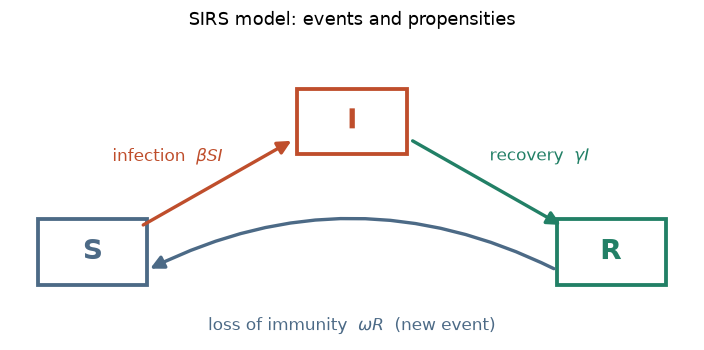

state-change vectors:
 [[-1  1  0]
 [ 0 -1  1]
 [ 1  0 -1]]


In [2]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 4.2)
pos = {"S": (1.2, 1.2), "I": (5, 3.0), "R": (8.8, 1.2)}
col = {"S": "#4C6A86", "I": "#BF4E2C", "R": "#228066"}
for k, (x, y) in pos.items():
    ax.add_patch(plt.Rectangle((x-0.8, y-0.45), 1.6, 0.9, fc="white", ec=col[k], lw=2.5))
    ax.text(x, y, k, ha="center", va="center", fontsize=18, fontweight="bold", color=col[k])
arrow = dict(arrowstyle="-|>", lw=2.2, mutation_scale=18)
ax.annotate("", xy=(4.15, 2.75), xytext=(1.9, 1.55), arrowprops=dict(color=col["I"], **arrow))
ax.text(2.3, 2.45, r"infection  $\beta S I$", color=col["I"], ha="center", fontsize=11)
ax.annotate("", xy=(8.1, 1.55), xytext=(5.85, 2.75), arrowprops=dict(color=col["R"], **arrow))
ax.text(7.75, 2.45, r"recovery  $\gamma I$", color=col["R"], ha="center", fontsize=11)
ax.annotate("", xy=(2.0, 0.95), xytext=(8.0, 0.95),
            arrowprops=dict(color=col["S"], connectionstyle="arc3,rad=0.25", **arrow))
ax.text(5, 0.12, r"loss of immunity  $\omega R$  (new event)", color=col["S"], ha="center", fontsize=11)
ax.set_title("SIRS model: events and propensities", fontsize=12)
plt.show()

# State-change matrix used by the SSA below (rows = events, columns = [S, I, R])
NU = np.array([[-1, +1,  0],    # infection
               [ 0, -1, +1],    # recovery
               [+1,  0, -1]])   # loss of immunity
print("state-change vectors:\n", NU)

## B. ODE model and equilibria (Q3)

Summing the contribution of each event (mean-field/rate equations, as derived from the CME in the lecture):

$$\frac{dS}{dt}=-\beta SI+\omega R,\qquad
\frac{dI}{dt}=\beta SI-\gamma I,\qquad
\frac{dR}{dt}=\gamma I-\omega R .$$

Adding the three equations gives $\frac{d}{dt}(S+I+R)=0$, so $S+I+R=N$ is conserved.

**Equilibria.** Set all derivatives to zero.

* From $dR/dt=0$: $R^*=\dfrac{\gamma}{\omega}I^*$.
* From $dI/dt=0$: $I^*(\beta S^*-\gamma)=0$, so either $I^*=0$ or $S^*=\gamma/\beta$.

1. **Disease-free equilibrium (DFE):** $I^*=0\Rightarrow R^*=0,\ S^*=N$. It always exists.
2. **Endemic equilibrium:** $S^*=\gamma/\beta$. Using $N=S^*+I^*+R^*$:
$$N=\frac{\gamma}{\beta}+I^*\Big(1+\frac{\gamma}{\omega}\Big)
\;\Longrightarrow\;
\boxed{I^*=\frac{\omega}{\omega+\gamma}\Big(N-\frac{\gamma}{\beta}\Big)},\qquad
R^*=\frac{\gamma}{\omega+\gamma}\Big(N-\frac{\gamma}{\beta}\Big),\qquad S^*=\frac{\gamma}{\beta}.$$

$I^*>0$ **if and only if** $N>N_c=\gamma/\beta$, equivalently $\mathcal R_0=\beta N/\gamma>1$. With the project parameters $N_c=0.15/0.01=15$.

**Dependence of $I^*$ on parameters.**
* $I^*$ grows linearly with $N$ (slope $\omega/(\omega+\gamma)$): more people sustain more infection, but $S^*=\gamma/\beta$ does **not** depend on $N$ – extra people end up in $I$ and $R$.
* $I^*$ increases with $\beta$ (through $N_c=\gamma/\beta$) and with $\omega$ (faster return to $S$ replenishes susceptibles; for $\omega\to\infty$, $I^*\to N-\gamma/\beta$, the SIS limit; for $\omega\to0$, $I^*\to0$, the SIR model with permanent immunity has no endemic state).
* $I^*$ decreases with $\gamma$ (shorter infectious period; it lowers the prefactor and raises $N_c$).

**Stability (reduced system).** Eliminating $R=N-S-I$, the Jacobian at the endemic point is
$J=\begin{pmatrix}-\beta I^*-\omega & -\beta S^*-\omega\\ \beta I^* & 0\end{pmatrix}$, with $\operatorname{tr}J=-(\beta I^*+\omega)<0$ and $\det J=\beta I^*(\beta S^*+\omega)>0$ whenever $I^*>0$: the endemic equilibrium is stable when it exists. For $N<N_c$ the DFE is stable (the infection dies out). Complex eigenvalues (damped oscillations) occur when $\operatorname{tr}^2<4\det$.

In [3]:
# Symbolic check of the algebra
S, I, R, N_, b, g, w = sp.symbols("S I R N beta gamma omega", positive=True)
dS = -b*S*I + w*R
dI =  b*S*I - g*I
dR =  g*I - w*R
sols = sp.solve([dS, dI, dR, S + I + R - N_], [S, I, R], dict=True)
for s in sols:
    print({k: sp.simplify(v) for k, v in s.items()})

# Numerical values with the project parameters
N_crit = gamma / beta
def endemic(N, beta=beta, gamma=gamma, omega=omega):
    Ie = max(0.0, omega/(omega+gamma) * (N - gamma/beta))
    return gamma/beta if Ie > 0 else N, Ie, gamma/omega*Ie

print(f"\nCritical population size N_c = gamma/beta = {N_crit:.1f}")
for N in [10, 15, 20, 30, 50, 100]:
    Se, Ie, Re = endemic(N)
    print(f"N={N:3d}  R0={beta*N/gamma:5.2f}  S*={Se:6.2f}  I*={Ie:6.2f}  R*={Re:6.2f}")

{I: omega*(N*beta - gamma)/(beta*(gamma + omega)), R: gamma*(N*beta - gamma)/(beta*(gamma + omega)), S: gamma/beta}

Critical population size N_c = gamma/beta = 15.0
N= 10  R0= 0.67  S*= 10.00  I*=  0.00  R*=  0.00
N= 15  R0= 1.00  S*= 15.00  I*=  0.00  R*=  0.00
N= 20  R0= 1.33  S*= 15.00  I*=  0.71  R*=  4.29
N= 30  R0= 2.00  S*= 15.00  I*=  2.14  R*= 12.86
N= 50  R0= 3.33  S*= 15.00  I*=  5.00  R*= 30.00
N=100  R0= 6.67  S*= 15.00  I*= 12.14  R*= 72.86


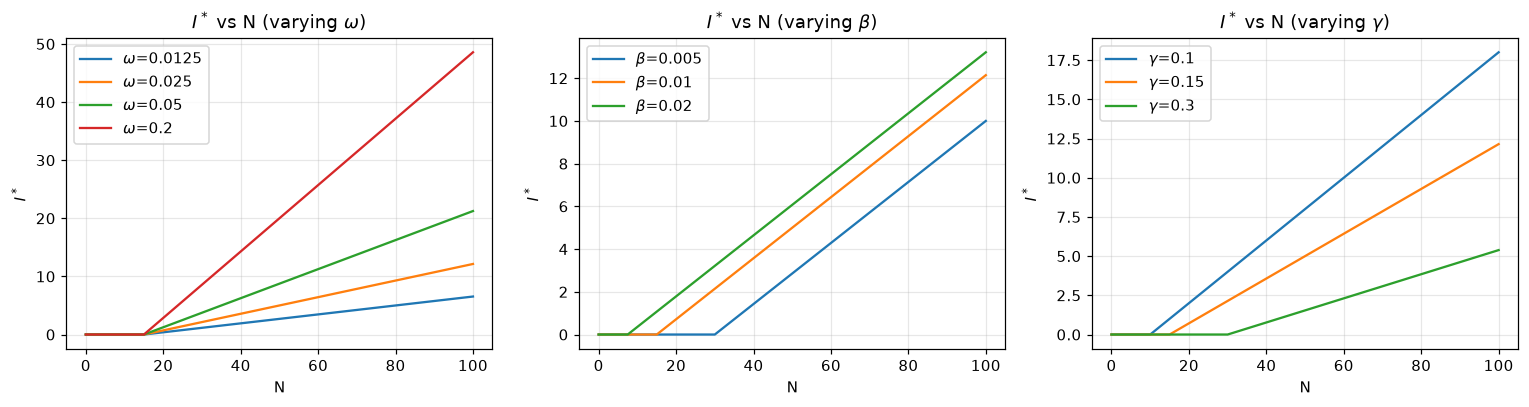

In [4]:
# How I* depends on N and on the parameters
Ns = np.linspace(0, 100, 401)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for om in [0.0125, 0.025, 0.05, 0.2]:
    axs[0].plot(Ns, np.maximum(0, om/(om+gamma)*(Ns-gamma/beta)), label=fr"$\omega$={om}")
axs[0].set(xlabel="N", ylabel="$I^*$", title=r"$I^*$ vs N (varying $\omega$)"); axs[0].legend()
for be in [0.005, 0.01, 0.02]:
    axs[1].plot(Ns, np.maximum(0, omega/(omega+gamma)*(Ns-gamma/be)), label=fr"$\beta$={be}")
axs[1].set(xlabel="N", ylabel="$I^*$", title=r"$I^*$ vs N (varying $\beta$)"); axs[1].legend()
for ga in [0.1, 0.15, 0.3]:
    axs[2].plot(Ns, np.maximum(0, omega/(omega+ga)*(Ns-ga/beta)), label=fr"$\gamma$={ga}")
axs[2].set(xlabel="N", ylabel="$I^*$", title=r"$I^*$ vs N (varying $\gamma$)"); axs[2].legend()
plt.tight_layout(); plt.show()

## C. Numerical solution of the ODE (Q4)

**Why these parameters?**
* $1/\gamma=1/0.15\approx 6.7$ days: a mean infectious period of about a week (acute infection, e.g. influenza-like).
* $1/\omega=40$ days: immunity lasts about six weeks – long compared with the infectious period ($\omega\ll\gamma$), but short enough to see re-infection cycles within one year.
* $\beta=0.01$ per person per day with $N$ of order tens: the threshold $N_c=\gamma/\beta=15$ falls inside $N\in[10,100]$. So $N=10$ gives $\mathcal R_0=0.67<1$ (no endemic state) and $N\ge 20$ gives $\mathcal R_0>1$.
* $T=365$ days is about nine immunity periods ($1/\omega=40$ d) so that transients, including the oscillations around the endemic state, have time to settle, and it is long enough for stochastic fade-out to show up.

Initial condition used for both ODE and SSA: one infectious individual, $(S_0,I_0,R_0)=(N-1,1,0)$.

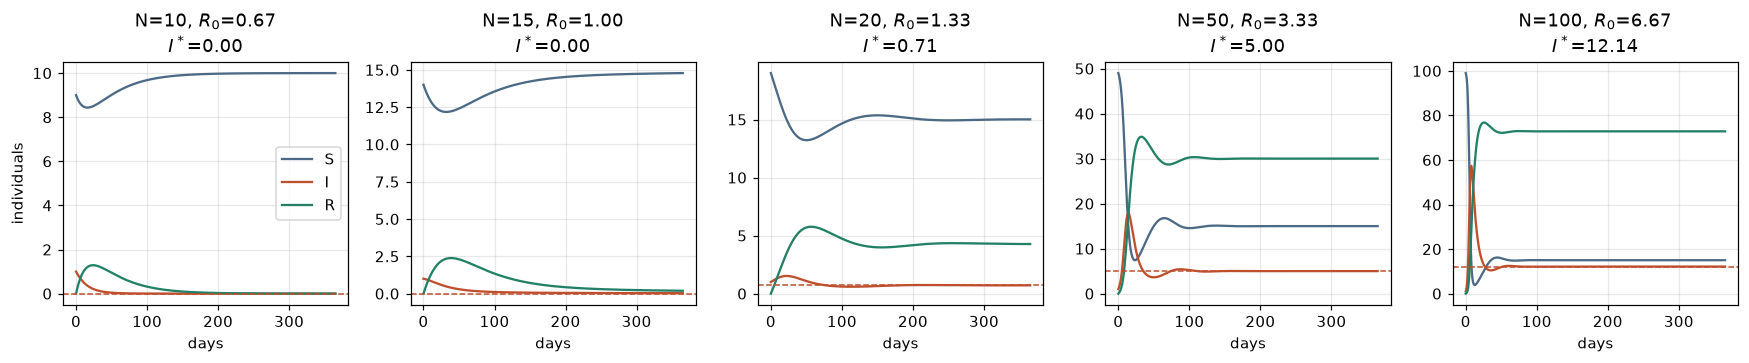

In [5]:
def sirs_rhs(t, y, beta, gamma, omega):
    S, I, R = y
    return [-beta*S*I + omega*R,
             beta*S*I - gamma*I,
             gamma*I - omega*R]

def solve_sirs(N, I0=1, beta=beta, gamma=gamma, omega=omega, t_max=T_MAX, n=2000):
    t_eval = np.linspace(0, t_max, n)
    sol = solve_ivp(sirs_rhs, (0, t_max), [N-I0, I0, 0], args=(beta, gamma, omega),
                    t_eval=t_eval, rtol=1e-9, atol=1e-12)
    return sol.t, sol.y

Ns_demo = [10, 15, 20, 50, 100]
fig, axs = plt.subplots(1, len(Ns_demo), figsize=(16, 3.4))
for ax, N in zip(axs, Ns_demo):
    t, y = solve_sirs(N)
    ax.plot(t, y[0], label="S", color="#4C6A86"); ax.plot(t, y[1], label="I", color="#BF4E2C")
    ax.plot(t, y[2], label="R", color="#228066")
    Se, Ie, Re = endemic(N)
    ax.axhline(Ie, ls="--", color="#BF4E2C", lw=1)
    ax.set_title(f"N={N}, $R_0$={beta*N/gamma:.2f}\n$I^*$={Ie:.2f}"); ax.set_xlabel("days")
axs[0].set_ylabel("individuals"); axs[0].legend()
plt.tight_layout(); plt.show()

In [6]:
# Does the numerical solution converge to the analytical equilibrium?
print(f"{'N':>4} {'I(365) ODE':>11} {'I* theory':>10} {'S(365)':>8} {'S* theory':>10}")
for N in [10, 14, 15, 16, 20, 30, 50, 100]:
    t, y = solve_sirs(N, t_max=3000, n=500)
    Se, Ie, Re = endemic(N)
    print(f"{N:4d} {y[1,-1]:11.4f} {Ie:10.4f} {y[0,-1]:8.3f} {Se:10.3f}")

   N  I(365) ODE  I* theory   S(365)  S* theory
  10      0.0000     0.0000   10.000     10.000
  14      0.0000     0.0000   14.000     14.000
  15      0.0044     0.0000   14.969     15.000
  16      0.1429     0.1429   15.000     15.000
  20      0.7143     0.7143   15.000     15.000
  30      2.1429     2.1429   15.000     15.000
  50      5.0000     5.0000   15.000     15.000
 100     12.1429    12.1429   15.000     15.000


**Reading of the ODE results.**
* $N=10<N_c$: the infection declines monotonically to $I\to 0$ (no outbreak since $\mathcal R_0<1$); everyone returns to $S$ over time.
* $N=15=N_c$: borderline ($I^*=0$); decay is very slow.
* $N>15$: a first epidemic peak, then damped oscillations, converging to the endemic equilibrium $I^*=(N-15)/7$, $S^*=15$ – the values in the table above match the analysis (the table uses a longer horizon of 3000 days because the approach to equilibrium near the threshold is slow).

## D. Gillespie SSA with loss of immunity (Q5)

We extend Monday's SIR code with the third event. As in the lecture, the **direct method** draws one waiting time $\tau\sim\text{Exp}(a_0)$ with $a_0=\sum_j a_j$, and picks event $j$ with probability $a_j/a_0$ (equivalent to the first-reaction method used on Monday). The SSA produces exact sample paths of the process described by the CME.

In [7]:
def ssa_sirs(N, I0=1, beta=beta, gamma=gamma, omega=omega, t_max=T_MAX, rng=None):
    '''Gillespie direct method for the SIRS model. Returns arrays (times, states[n,3]).
    The run stops when I = 0 (absorbing state: no infection can ever restart) or t >= t_max.'''
    rng = np.random.default_rng() if rng is None else rng
    S, I, R = N - I0, I0, 0
    t = 0.0
    times, states = [t], [(S, I, R)]
    while t < t_max and I > 0:
        a = (beta*S*I, gamma*I, omega*R)       # propensities: infection, recovery, waning
        a0 = a[0] + a[1] + a[2]
        t += rng.exponential(1.0/a0)
        u = rng.random() * a0
        if u < a[0]:                           # infection  S -> I
            S -= 1; I += 1
        elif u < a[0] + a[1]:                  # recovery   I -> R
            I -= 1; R += 1
        else:                                  # waning     R -> S
            R -= 1; S += 1
        times.append(t); states.append((S, I, R))
    return np.array(times), np.array(states)

# sanity check: population conserved
tt, ss = ssa_sirs(50, rng=np.random.default_rng(1))
print("events:", len(tt)-1, "| N conserved:", np.all(ss.sum(axis=1) == 50), "| final I:", ss[-1, 1], "at t =", round(tt[-1], 1))

events: 1 | N conserved: True | final I: 0 at t = 1.7


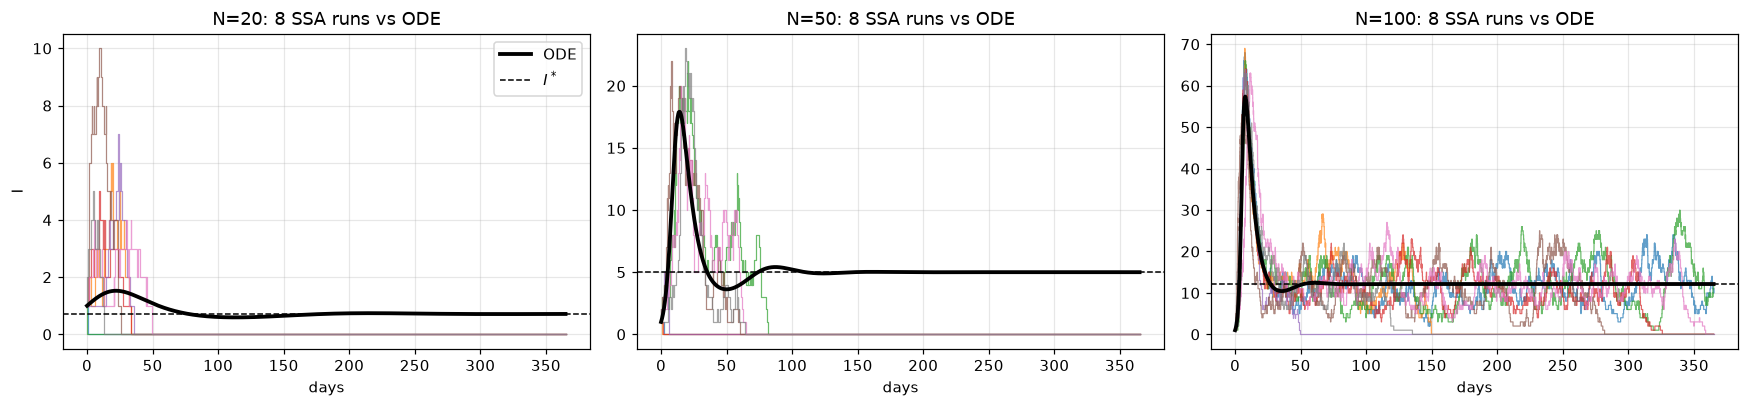

In [8]:
def step_at(times, vals, grid):
    '''Value of a piecewise-constant trajectory on a time grid (stays at the last value after the end).'''
    idx = np.searchsorted(times, grid, side="right") - 1
    return vals[idx]

fig, axs = plt.subplots(1, 3, figsize=(16, 3.8), sharex=True)
rng = np.random.default_rng(2026)
for ax, N in zip(axs, [20, 50, 100]):
    t, y = solve_sirs(N)
    for _ in range(8):
        ts, ss = ssa_sirs(N, rng=rng)
        ax.step(np.append(ts, T_MAX), np.append(ss[:, 1], ss[-1, 1]), where="post", lw=0.8, alpha=0.7)
    ax.plot(t, y[1], "k", lw=2.5, label="ODE")
    ax.axhline(endemic(N)[1], color="k", ls="--", lw=1, label="$I^*$")
    ax.set_title(f"N={N}: 8 SSA runs vs ODE"); ax.set_xlabel("days")
axs[0].set_ylabel("I"); axs[0].legend()
plt.tight_layout(); plt.show()

### Many runs: summary statistics as a function of $N$

For each $N$ we run the SSA `N_RUNS` times and record:
* **P(infection present at day 365)** – fraction of runs that have not gone extinct ($I>0$ at $t=365$). A run with $I=0$ is absorbed (no source of new infection) – this is the stochastic fade-out that the ODE cannot show.
* **Fade-out time** among the runs that went extinct.
* **Maximum of $I$** over the run versus the ODE maximum.
* **Mean $I$ in the stochastic endemic state**: time-average of $I$ over days 100–365, for runs still infected at day 365, compared with $I^*$ and with the ODE value.

In [9]:
N_RUNS = 500
T_BURN = 100.0
grid = np.linspace(T_BURN, T_MAX, 800)

def ssa_ensemble(N, n_runs=N_RUNS, seed=0):
    rng = np.random.default_rng(seed)
    out = dict(alive=[], t_ext=[], Imax=[], Imean=[], I_end=[])
    for _ in range(n_runs):
        ts, ss = ssa_sirs(N, rng=rng)
        alive = ss[-1, 1] > 0
        out["alive"].append(alive)
        out["Imax"].append(ss[:, 1].max())
        out["I_end"].append(ss[-1, 1] if alive else 0)
        if alive:
            out["Imean"].append(step_at(ts, ss[:, 1], grid).mean())
        else:
            out["t_ext"].append(ts[-1])
    return {k: np.array(v) for k, v in out.items()}

N_list = [10, 12, 15, 18, 20, 25, 30, 40, 50, 70, 100]
results = {N: ssa_ensemble(N, seed=N) for N in N_list}

In [10]:
import pandas as pd
rows = []
for N in N_list:
    r = results[N]; t, y = solve_sirs(N)
    Ie = endemic(N)[1]
    rows.append({
        "N": N, "R0": round(beta*N/gamma, 2),
        "ODE endemic?": Ie > 0,
        "I* (ODE)": round(Ie, 2),
        "P(alive at 365)": r["alive"].mean(),
        "median fade-out day": np.median(r["t_ext"]) if len(r["t_ext"]) else np.nan,
        "max I  SSA (mean)": r["Imax"].mean(),
        "max I  ODE": y[1].max(),
        "mean I | alive (SSA)": r["Imean"].mean() if len(r["Imean"]) else np.nan,
    })
df = pd.DataFrame(rows).round(2)
df

,N,R0,ODE endemic?,I* (ODE),P(alive at 365),median fade-out day,max I SSA (mean),max I ODE,mean I | alive (SSA)
0,10,0.67,False,0.00,0.00,5.53,1.67,1.00,NaN
1,12,0.80,False,0.00,0.00,6.05,1.87,1.00,NaN
2,15,1.00,False,0.00,0.00,5.88,2.01,1.00,NaN
3,18,1.20,True,0.43,0.00,7.35,2.64,1.14,NaN
4,20,1.33,True,0.71,0.00,6.13,2.83,1.52,NaN
5,25,1.67,True,1.43,0.00,10.07,4.11,3.22,NaN
6,30,2.00,True,2.14,0.00,11.52,5.32,5.54,NaN
7,40,2.67,True,3.57,0.00,42.15,10.45,11.26,NaN
8,50,3.33,True,5.00,0.00,48.07,14.73,17.90,5.12
9,70,4.67,True,7.86,0.07,64.50,27.24,32.80,8.00


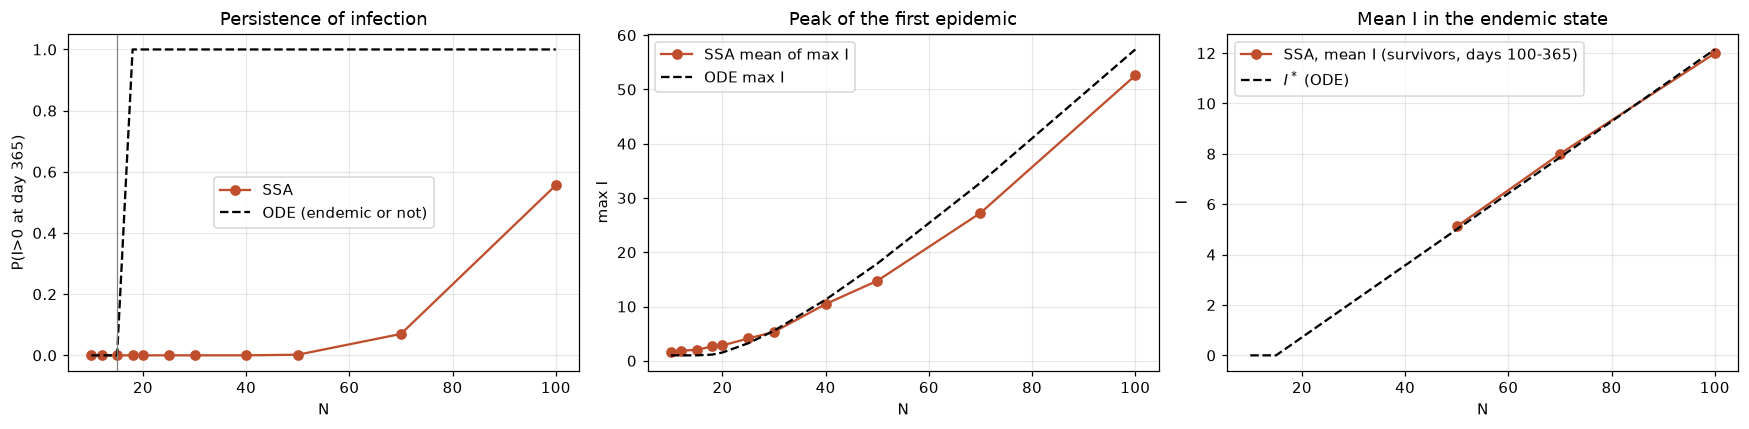

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
Ns_f = np.array(N_list)
Ie_arr = np.array([endemic(N)[1] for N in N_list])

axs[0].plot(Ns_f, [results[N]["alive"].mean() for N in N_list], "o-", color="#BF4E2C", label="SSA")
axs[0].plot(Ns_f, (Ns_f > N_crit).astype(float), "k--", label="ODE (endemic or not)")
axs[0].axvline(N_crit, color="gray", lw=0.8)
axs[0].set(xlabel="N", ylabel="P(I>0 at day 365)", title="Persistence of infection", ylim=(-0.05, 1.05)); axs[0].legend()

axs[1].plot(Ns_f, [results[N]["Imax"].mean() for N in N_list], "o-", color="#BF4E2C", label="SSA mean of max I")
axs[1].plot(Ns_f, [solve_sirs(N)[1][1].max() for N in N_list], "k--", label="ODE max I")
axs[1].set(xlabel="N", ylabel="max I", title="Peak of the first epidemic"); axs[1].legend()

axs[2].plot(Ns_f, [results[N]["Imean"].mean() if len(results[N]["Imean"]) else np.nan for N in N_list],
            "o-", color="#BF4E2C", label="SSA, mean I (survivors, days 100-365)")
axs[2].plot(Ns_f, Ie_arr, "k--", label="$I^*$ (ODE)")
axs[2].set(xlabel="N", ylabel="I", title="Mean I in the endemic state"); axs[2].legend()
plt.tight_layout(); plt.show()

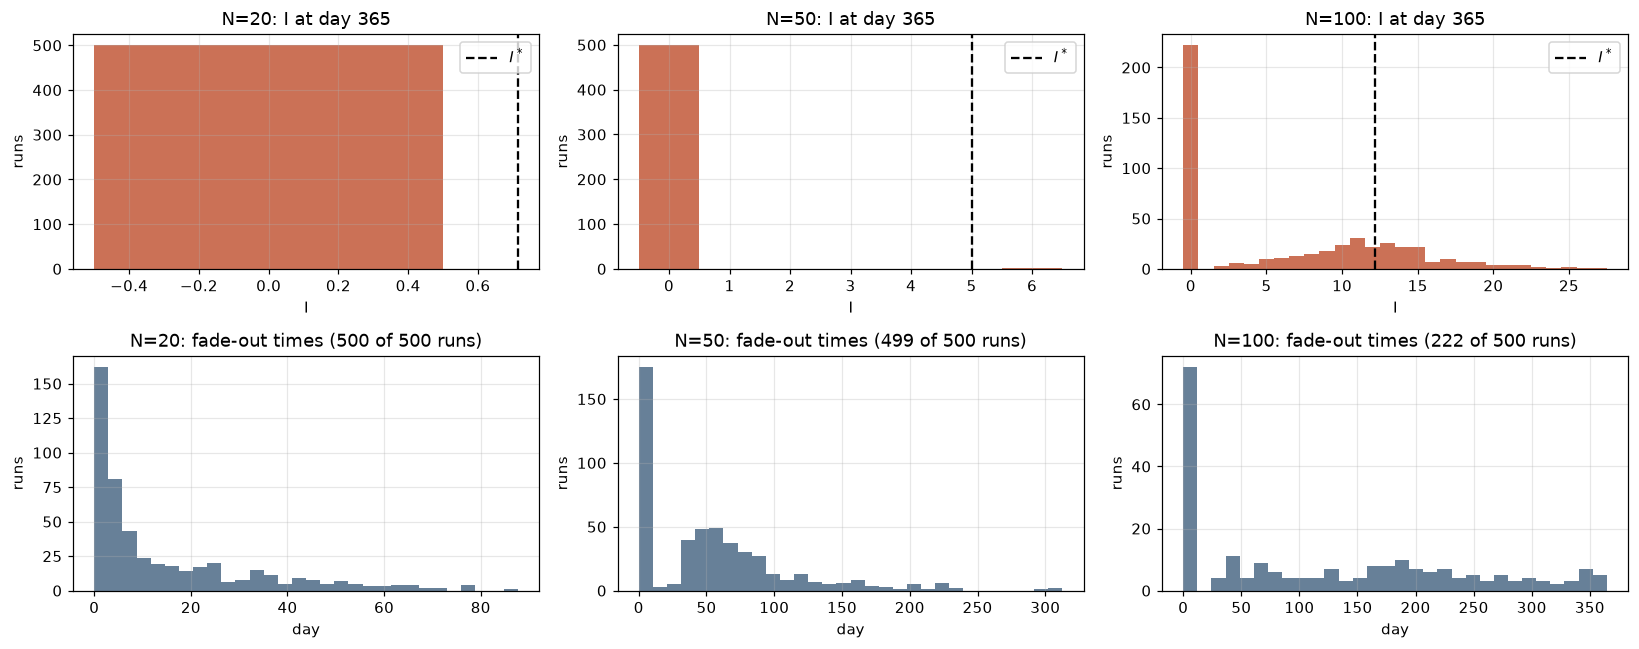

In [12]:
# Distribution of I at day 365 and of extinction times for a few N
fig, axs = plt.subplots(2, 3, figsize=(15, 6))
for j, N in enumerate([20, 50, 100]):
    r = results[N]
    axs[0, j].hist(r["I_end"], bins=np.arange(-0.5, r["I_end"].max()+1.5, 1), color="#BF4E2C", alpha=0.8)
    axs[0, j].axvline(endemic(N)[1], color="k", ls="--", label="$I^*$")
    axs[0, j].set(title=f"N={N}: I at day 365", xlabel="I", ylabel="runs"); axs[0, j].legend()
    if len(r["t_ext"]):
        axs[1, j].hist(r["t_ext"], bins=30, color="#4C6A86", alpha=0.85)
    axs[1, j].set(title=f"N={N}: fade-out times ({len(r['t_ext'])} of {N_RUNS} runs)", xlabel="day", ylabel="runs")
plt.tight_layout(); plt.show()

### How to read these results (answers to the Q5 prompts)

*Numbers below come from the run above (500 runs per N, one infectious individual at t=0, seeds fixed in the code). Re-check them if you change the settings.*

1. **Does the SSA always generate an endemic equilibrium when the ODE does?** No. For every $N$ from 18 to 100 the ODE predicts an endemic state ($I^*>0$), yet in the SSA **0 of 500 runs** still had infection at day 365 for $N\le40$, 1 of 500 at $N=50$, 35 of 500 (7%) at $N=70$ and 278 of 500 (56%) at $N=100$. The infection is lost when $I$ hits 0, which is absorbing (nobody can be infected without an infectious person). The ODE never reaches $I=0$ because $I$ is continuous.
2. **How frequently do the predictions differ, as a function of $N$?** The two models disagree about persistence for all $N>15$ up to at least $N=100$ (agreement is only partial at $N=100$). They agree for $N\le15$ (both: no endemic state; SSA median fade-out within about 6 days). Fade-out time lengthens with $N$ (median about 10 days at $N=25$, 48 at $N=50$, 100 at $N=100$).
3. **Maximum of $I$.** For small $N$ the SSA peak is *higher* than the ODE peak (e.g. $N=20$: 2.8 vs 1.5) because the ODE with $I_0=1$ and $\mathcal R_0$ near 1 only declines or barely rises, whereas the SSA is integer-valued and can fluctuate upward before dying out. For larger $N$ the SSA mean peak is *lower* than the ODE peak ($N=50$: 14.7 vs 17.9; $N=100$: 52.6 vs 57.4), because some runs die out before any large epidemic and the others take off at random times.
4. **Mean $I$ in the stochastic endemic state versus $I^*$.** Only runs still infected at day 365 can be averaged. For those, the time-average over days 100–365 is close to the ODE equilibrium: 5.1 vs $I^*=5.0$ ($N=50$), 8.0 vs 7.9 ($N=70$), 12.0 vs 12.1 ($N=100$). So when an endemic state is reached it fluctuates around the ODE value, as expected when numbers are large enough that the ODE mean approximation is reasonable. For $N\lesssim40$ there are no (or almost no) surviving runs to average.

**Important caveat on $I^*$ for small $N$.** For $N=18,20,25$ the ODE equilibrium is $I^*=0.43,0.71,1.43$: less than one individual. A fraction of a person cannot persist in a discrete system, which is exactly why the SSA never shows an endemic state there. The ODE threshold $N>15$ is therefore necessary but not sufficient for persistence in a small stochastic population.

**Take-home message.** The ODE describes the deterministic large-population limit. For small populations, stochastic extinction is a new outcome that changes whether the disease persists, even when $\mathcal R_0>1$.